# 05 · Feasibility and Infeasibility

The capability no heuristic has. Take a feasible roster and tighten the rules until no valid schedule can exist — and watch CP-SAT **prove** it, reporting `INFEASIBLE` definitively rather than looping forever or returning a broken schedule.

'The solver says it is impossible' is a valuable, actionable answer: it tells you to relax a rule, not to keep searching.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from repo root or notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt

from src.persistence import save_figure, save_json

print("figures ->", save_figure.__module__, "| ready")

figures -> src.persistence | ready


## Sweep the coverage demand until the roster breaks
Start from the comfortable instance and raise the nurses-required-per-shift. At some point there are simply not enough nurses — and the solver proves it.

In [2]:
from dataclasses import replace

from src.datasets import instances
from src.models.nurse_roster import solve_roster

base = instances.feasible_roster()
sweep = []
for demand in range(1, 4):
    problem = replace(base, demand=(demand, demand, demand))
    res = solve_roster(problem, time_limit=10.0)
    sweep.append({
        "demand_per_shift": demand,
        "status": res.stats.status_name,
        "feasible": res.is_feasible,
        "wall_time": res.stats.wall_time,
    })
    print(f"demand={demand} -> {res.stats.status_name}")
save_json("05_feasibility_sweep", sweep)

demand=1 -> OPTIMAL
demand=2 -> INFEASIBLE
demand=3 -> INFEASIBLE


PosixPath('/workspaces/constraint_programming_101/outputs/data/05_feasibility_sweep.json')

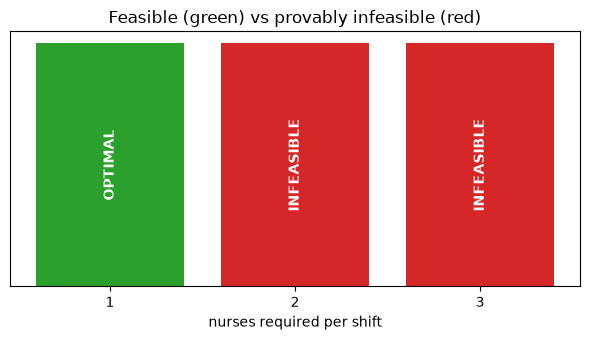

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
labels = [str(row["demand_per_shift"]) for row in sweep]
colours = ["tab:green" if row["feasible"] else "tab:red" for row in sweep]
ax.bar(labels, [1] * len(sweep), color=colours)
for i, row in enumerate(sweep):
    ax.text(i, 0.5, row["status"], ha="center", va="center", rotation=90,
            color="white", fontweight="bold")
ax.set_xlabel("nurses required per shift")
ax.set_yticks([])
ax.set_title("Feasible (green) vs provably infeasible (red)")
fig.tight_layout()
save_figure("05_feasibility_flip", fig)
plt.show()

## What to do with an infeasible model
The over-constrained instance below cannot be satisfied. The actionable response is to decide **which rule to relax** — lower the demand, hire a nurse, or soften the days-off guarantee. CP makes infeasibility a first-class, provable verdict.

In [4]:
from src.models.sudoku import solve_sudoku

inf = solve_roster(instances.infeasible_roster(), time_limit=10.0)
print("roster over-constrained ->", inf.stats.status_name,
      "| infeasible proven:", inf.stats.is_infeasible)
save_json("05_infeasible_roster", instances.infeasible_roster())

bad_sudoku = solve_sudoku(instances.unsolvable_sudoku(), time_limit=10.0)
print("sudoku over-specified ->", bad_sudoku.stats.status_name,
      "| infeasible proven:", bad_sudoku.stats.is_infeasible)

roster over-constrained -> INFEASIBLE | infeasible proven: True
sudoku over-specified -> INFEASIBLE | infeasible proven: True


No hand-written heuristic can tell you a problem is *impossible*. A CP solver can, with proof — which is often the most useful thing it can say.